# Assignment 11: CNN Image Classification

**Dataset:** Tiny ImageNet, using 3 classes with 200 images each (600 images of size 64×64×3).



## Dataset Setup

In [1]:
!wget -q -nc https://cs231n.stanford.edu/tiny-imagenet-200.zip
!unzip -q -n tiny-imagenet-200.zip

In [2]:
import os

dataset_path = "/content/tiny-imagenet-200"

print("Total Classes:", len(os.listdir(dataset_path + "/train")))
print("Dataset Downloaded Successfully!")

Total Classes: 200
Dataset Downloaded Successfully!


In [3]:
import os
import shutil
import glob

source_path = "/content/tiny-imagenet-200/train"
target_path = "/content/selected_dataset"

classes = sorted(os.listdir(source_path))[:3]

# Start clean so a second run cannot leave more than 200 images per class.
shutil.rmtree(target_path, ignore_errors=True)
os.makedirs(target_path, exist_ok=True)

for cls in classes:
    os.makedirs(target_path + "/" + cls, exist_ok=True)

    # sorted() selects the same 200 images on every run.
    images = sorted(glob.glob(source_path + "/" + cls + "/images/*.JPEG"))[:200]

    for img in images:
        shutil.copy(img, target_path + "/" + cls)

    print(cls, ":", len(images), "images")

print("Total Images:", sum(len(os.listdir(target_path + "/" + c)) for c in classes))

n01443537 : 200 images
n01629819 : 200 images
n01641577 : 200 images
Total Images: 600


In [4]:
for cls in classes:
    print(cls, ":", len(os.listdir(target_path + "/" + cls)))

n01443537 : 200
n01629819 : 200
n01641577 : 200


In [5]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# Makes the results repeatable. Small differences are still possible on a GPU.
tf.keras.utils.set_random_seed(42)

print("Class Names:", {cls: i for i, cls in enumerate(classes)})

Class Names: {'n01443537': 0, 'n01629819': 1, 'n01641577': 2}


## Task 1: CNN Basics on a 3×3 Matrix

This task applies each CNN building block to a random 3×3 matrix.

In [6]:
matrix = np.random.rand(3, 3, 1).astype("float32")

input_data = np.expand_dims(matrix, axis=0)

# With a 3x3 kernel and stride 1, padding='same' is equivalent to P=1.
conv = tf.keras.layers.Conv2D(1, (3, 3), padding='same')(input_data)

relu = tf.keras.layers.ReLU()(conv)

sigmoid = tf.keras.layers.Activation('sigmoid')(conv)

pool = tf.keras.layers.MaxPooling2D(pool_size=(2, 2))(conv)

print("Original Matrix:\n", matrix[:, :, 0])
print("Convolution Output:\n", conv.numpy()[0, :, :, 0])
print("ReLU Output:\n", relu.numpy()[0, :, :, 0])
print("Sigmoid Output:\n", sigmoid.numpy()[0, :, :, 0])
print("Max Pooling Output:\n", pool.numpy()[0, :, :, 0])

Original Matrix:
 [[0.37454012 0.9507143  0.7319939 ]
 [0.5986585  0.15601864 0.15599452]
 [0.05808361 0.8661761  0.601115  ]]
Convolution Output:
 [[-0.24052897  0.1298691   0.16230196]
 [-0.34748238  0.19243214  0.7758179 ]
 [ 0.2110262  -0.03464269  0.25102004]]
ReLU Output:
 [[0.         0.1298691  0.16230196]
 [0.         0.19243214 0.7758179 ]
 [0.2110262  0.         0.25102004]]
Sigmoid Output:
 [[0.440156   0.53242177 0.54048663]
 [0.4139931  0.54796016 0.6847781 ]
 [0.5525616  0.4913402  0.5624275 ]]
Max Pooling Output:
 [[0.19243214]]


In [7]:
min_pool = -tf.keras.layers.MaxPooling2D(pool_size=(2, 2))(-conv)

gap = tf.keras.layers.GlobalAveragePooling2D()(conv)

print("Min Pooling Output:\n", min_pool.numpy()[0, :, :, 0])
print("Global Average Pooling Output:\n", gap.numpy())

Min Pooling Output:
 [[-0.34748238]]
Global Average Pooling Output:
 [[0.12220148]]


In [8]:
flatten = tf.keras.layers.Flatten()(conv)

dense = tf.keras.layers.Dense(8, activation='relu')(flatten)

output = tf.keras.layers.Dense(3, activation='softmax')(dense)

print("Flatten Output Shape:", flatten.shape)
print("Dense Output Shape:", dense.shape)
print("Final Output:", output.numpy())

Flatten Output Shape: (1, 9)
Dense Output Shape: (1, 8)
Final Output: [[0.20254482 0.34079048 0.45666465]]


In [9]:
# Batch Normalization needs more than one sample. With a single sample, the
# batch mean equals the sample, so every output would be zero.
batch = tf.random.uniform((4, 8))

bn = tf.keras.layers.BatchNormalization()(batch, training=True)

drop = tf.keras.layers.Dropout(0.5)(bn, training=True)

print("Input Batch:\n", batch.numpy())
print("Batch Normalization Output:\n", bn.numpy())
print("Dropout Output:\n", drop.numpy())

Input Batch:
 [[0.6645621  0.44100678 0.3528825  0.46448255 0.03366041 0.68467236
  0.74011743 0.8724445 ]
 [0.22632635 0.22319686 0.3103881  0.7223358  0.13318717 0.5480639
  0.5746088  0.8996835 ]
 [0.00946367 0.5212307  0.6345445  0.1993283  0.72942245 0.54583454
  0.10756552 0.6767061 ]
 [0.6602763  0.33695042 0.60141766 0.21062577 0.8527372  0.44062173
  0.9485276  0.23752594]]
Batch Normalization Output:
 [[ 0.9641156   0.51941705 -0.824625    0.3010075  -1.1222427   1.4080782
   0.4732964   0.7527249 ]
 [-0.5756156  -1.3533376  -1.1120293   1.4898033  -0.8454945  -0.07301188
  -0.0581007   0.85480595]
 [-1.3375576   1.2091913   1.0803514  -0.9214482   0.8124217  -0.0971818
  -1.5576323   0.01917315]
 [ 0.94905734 -0.37527156  0.8563032  -0.86936283  1.1553155  -1.237884
   1.142437   -1.6267039 ]]
Dropout Output:
 [[ 1.9282312   1.0388341  -1.64925     0.602015   -2.2444854   2.8161564
   0.9465928   1.5054498 ]
 [ 0.         -2.7066753   0.          2.9796066   0.          0.
 

In [10]:
# Each model gets a new callback, so one model's best score cannot affect the next.
def make_early_stop():
    return tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True
    )

early_stop = make_early_stop()

print("Early Stopping Callback Created Successfully!")

Early Stopping Callback Created Successfully!


## Task 2: Custom CNN and Overfitting Analysis (600 Images)

This CNN uses the components from Task 1: convolution with padding, ReLU, Batch Normalization, max pooling, flattening, dense layers, Dropout, and Early Stopping. The data split is 70% training, 15% validation, and 15% testing.

In [11]:
from sklearn.model_selection import train_test_split

images = []
labels = []

for i, cls in enumerate(classes):
    files = sorted(os.listdir(target_path + "/" + cls))

    for file in files:
        img = tf.keras.utils.load_img(
            target_path + "/" + cls + "/" + file,
            target_size=(64, 64)
        )

        images.append(tf.keras.utils.img_to_array(img))
        labels.append(i)

images = np.array(images) / 255.0
labels = np.array(labels)

X_train, X_temp, y_train, y_temp = train_test_split(
    images, labels, test_size=0.30, random_state=42, stratify=labels
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

y_train = tf.keras.utils.to_categorical(y_train, 3)
y_val = tf.keras.utils.to_categorical(y_val, 3)
y_test = tf.keras.utils.to_categorical(y_test, 3)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (420, 64, 64, 3)
Validation: (90, 64, 64, 3)
Testing: (90, 64, 64, 3)


In [12]:
EPOCHS = 30

# momentum=0.9 updates the Batch Normalization averages faster. This dataset has
# only 14 batches per epoch, which is too few for the default of 0.99.
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(64, 64, 3)),

    tf.keras.layers.Conv2D(32, (3, 3), padding='same', activation='relu'),
    tf.keras.layers.BatchNormalization(momentum=0.9),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
    tf.keras.layers.BatchNormalization(momentum=0.9),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.5),

    tf.keras.layers.Dense(3, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     2,097,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,117,443 (8.08 MB)

 Trainable params: 2,117,251 (8.08 MB)

 Non-trainable params: 192 (768.00 B)

In [13]:
history = model.fit(
    X_train, y_train,
    epochs=EPOCHS,
    batch_size=32,
    validation_data=(X_val, y_val),
    callbacks=[early_stop]
)

Epoch 1/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 16s 613ms/step - accuracy: 0.5714 - loss: 4.2807 - val_accuracy: 0.3333 - val_loss: 7.5561
Epoch 2/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.7500 - loss: 1.3856 - val_accuracy: 0.4667 - val_loss: 5.7768
Epoch 3/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.8762 - loss: 0.3694 - val_accuracy: 0.6222 - val_loss: 3.2044
Epoch 4/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.8857 - loss: 0.3465 - val_accuracy: 0.8000 - val_loss: 1.1981
Epoch 5/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9024 - loss: 0.2145 - val_accuracy: 0.8222 - val_loss: 1.0477
Epoch 6/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9048 - loss: 0.2672 - val_accuracy: 0.8111 - val_loss: 0.7764
Epoch 7/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9333 - loss: 0.1831 - val_accuracy: 0.8333 - val_loss: 0.8094
Epoch 8/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9548 - loss: 0.1585 - val_accuracy: 0.8333 -

In [14]:
best_epoch = int(np.argmin(history.history['val_loss']))

print("Completed Epochs:", len(history.history['accuracy']))
print("Best Epoch (lowest validation loss):", best_epoch + 1)
print("Training Accuracy at Best Epoch:", history.history['accuracy'][best_epoch])
print("Validation Accuracy at Best Epoch:", history.history['val_accuracy'][best_epoch])

Completed Epochs: 15
Best Epoch (lowest validation loss): 10
Training Accuracy at Best Epoch: 0.9476190209388733
Validation Accuracy at Best Epoch: 0.8222222328186035


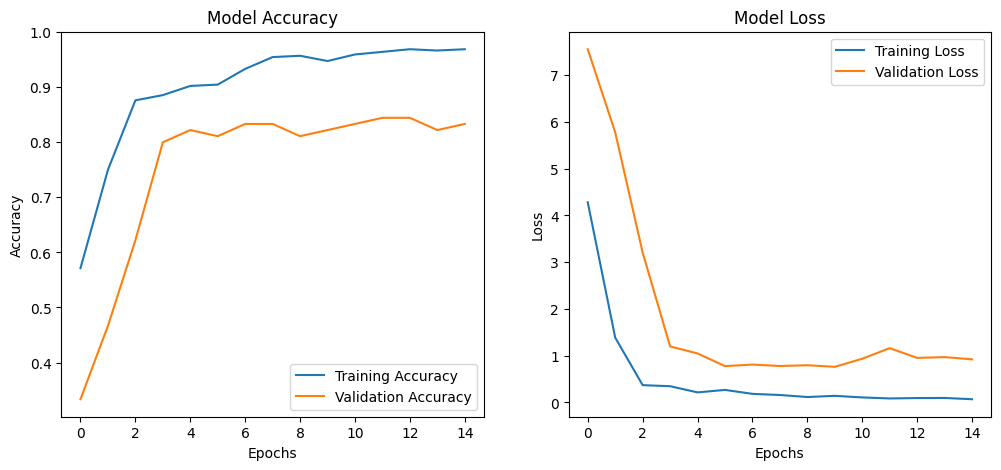

In [15]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.show()

### Overfitting and Underfitting Analysis

- **Underfitting:** training accuracy stays low because the model has not learned the patterns in the data.
- **Overfitting:** training loss keeps falling while validation loss rises, and training accuracy moves well above validation accuracy.

In [16]:
from IPython.display import Markdown, display

train_loss = history.history['loss']
val_loss = history.history['val_loss']
train_acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

last_epoch = len(val_loss) - 1
acc_gap = train_acc[best_epoch] - val_acc[best_epoch]
val_loss_rose = val_loss[last_epoch] > val_loss[best_epoch]
train_loss_fell = train_loss[last_epoch] < train_loss[best_epoch]

if train_acc[best_epoch] < 0.70:
    verdict = "The model shows **underfitting**, because training accuracy stayed below 70%."
elif val_loss_rose and train_loss_fell and acc_gap >= 0.15:
    verdict = "The model shows **clear overfitting** and no underfitting."
elif val_loss_rose and train_loss_fell and acc_gap >= 0.05:
    verdict = "The model shows **mild overfitting** and no underfitting."
else:
    verdict = "The model shows **no clear overfitting or underfitting**."

display(Markdown(f"""
{verdict}

- Validation loss reached its lowest value of {val_loss[best_epoch]:.4f} at epoch {best_epoch + 1}, and was {val_loss[last_epoch]:.4f} at the final epoch ({last_epoch + 1}).
- Training loss moved from {train_loss[best_epoch]:.4f} at epoch {best_epoch + 1} to {train_loss[last_epoch]:.4f} at the final epoch.
- At epoch {best_epoch + 1}, training accuracy was {train_acc[best_epoch]:.2%} and validation accuracy was {val_acc[best_epoch]:.2%}, a gap of {acc_gap * 100:.2f} percentage points.
- The test results below use the model from epoch {best_epoch + 1}, the best weights kept by Early Stopping.
"""))


The model shows **mild overfitting** and no underfitting.

- Validation loss reached its lowest value of 0.7609 at epoch 10, and was 0.9216 at the final epoch (15).
- Training loss moved from 0.1405 at epoch 10 to 0.0682 at the final epoch.
- At epoch 10, training accuracy was 94.76% and validation accuracy was 82.22%, a gap of 12.54 percentage points.
- The test results below use the model from epoch 10, the best weights kept by Early Stopping.


### Test Evaluation

The same function evaluates all four models, so their scores are directly comparable. Precision, recall, and F1 score are weighted averages.

In [17]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)
import seaborn as sns

results = {}

def evaluate_model(name, trained_model, X, y_one_hot):
    y_pred = np.argmax(trained_model.predict(X, verbose=0), axis=1)
    y_true = np.argmax(y_one_hot, axis=1)

    scores = {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, average='weighted', zero_division=0),
        'Recall': recall_score(y_true, y_pred, average='weighted', zero_division=0),
        'F1 Score': f1_score(y_true, y_pred, average='weighted', zero_division=0)
    }
    results[name] = scores

    print(classification_report(y_true, y_pred, target_names=classes, digits=4, zero_division=0))

    cm = confusion_matrix(y_true, y_pred, labels=range(len(classes)))

    plt.figure(figsize=(7, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=classes,
                yticklabels=classes)

    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(name + " Confusion Matrix")
    plt.show()

    total = int(cm.sum())
    correct = int(np.trace(cm))

    notes = [
        f"**{name}:** {correct} of {total} test images were classified correctly.",
        "",
        f"- Accuracy: {scores['Accuracy']:.2%}",
        f"- Precision: {scores['Precision']:.4f}",
        f"- Recall: {scores['Recall']:.4f}",
        f"- F1 Score: {scores['F1 Score']:.4f}"
    ]

    for i, cls in enumerate(classes):
        class_total = int(cm[i].sum())
        notes.append(f"- {cls}: {int(cm[i, i])} of {class_total} correct ({cm[i, i] / class_total:.2%})")

    errors = cm.copy()
    np.fill_diagonal(errors, 0)

    if errors.max() > 0:
        actual, predicted = np.unravel_index(np.argmax(errors), errors.shape)
        notes.append(
            f"- Most common error: {classes[actual]} predicted as "
            f"{classes[predicted]} ({int(errors[actual, predicted])} images)"
        )

    display(Markdown("\n".join(notes)))

In [18]:
test_loss, test_accuracy = model.evaluate(X_test, y_test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.8111 - loss: 0.5206
Test Loss: 0.5206170678138733
Test Accuracy: 0.8111110925674438


              precision    recall  f1-score   support

   n01443537     0.9310    0.9000    0.9153        30
   n01629819     0.7500    0.8000    0.7742        30
   n01641577     0.7586    0.7333    0.7458        30

    accuracy                         0.8111        90
   macro avg     0.8132    0.8111    0.8117        90
weighted avg     0.8132    0.8111    0.8117        90



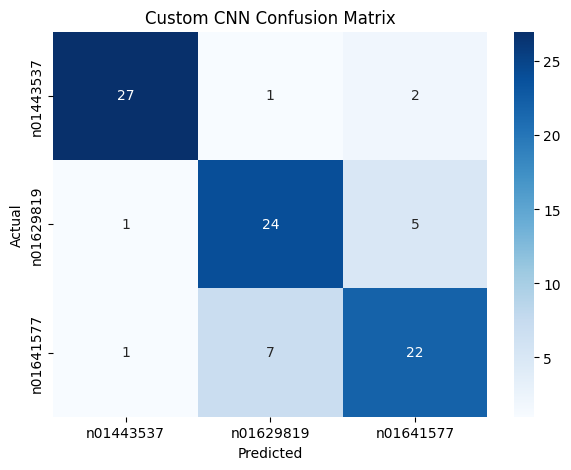

**Custom CNN:** 73 of 90 test images were classified correctly.

- Accuracy: 81.11%
- Precision: 0.8132
- Recall: 0.8111
- F1 Score: 0.8117
- n01443537: 27 of 30 correct (90.00%)
- n01629819: 24 of 30 correct (80.00%)
- n01641577: 22 of 30 correct (73.33%)
- Most common error: n01641577 predicted as n01629819 (7 images)

In [19]:
evaluate_model("Custom CNN", model, X_test, y_test)

## Task 3: Transfer Learning Comparison (600 Images)

### Objective
To implement VGG16, MobileNetV2, and ResNet50 on the same 600-image dataset, then compare their test accuracy, precision, recall, and F1 score with the custom CNN.

### Methodology
- Use the same training, validation, and test split as the custom CNN.
- Load each model with ImageNet weights and freeze its base layers.
- Resize images to 224×224 and apply each model's own `preprocess_input`, because each model expects a different input format.
- Add the same classification head to each model: global average pooling, a 128-unit dense layer, Dropout of 0.3, and a 3-class output layer.
- Train each model with the same settings and Early Stopping.

In [20]:
from tensorflow.keras.applications import VGG16, MobileNetV2, ResNet50
from tensorflow.keras.applications.vgg16 import preprocess_input as vgg_preprocess
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mobilenet_preprocess
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model

# X_train, X_val, and X_test are scaled to 0-1, but preprocess_input expects 0-255.
def prepare_images(X, preprocess):
    resized = tf.image.resize(X, (224, 224)).numpy() * 255.0
    return preprocess(resized)

### VGG16

In [21]:
X_train_vgg = prepare_images(X_train, vgg_preprocess)
X_val_vgg = prepare_images(X_val, vgg_preprocess)
X_test_vgg = prepare_images(X_test, vgg_preprocess)

print("Training Shape:", X_train_vgg.shape)
print("Validation Shape:", X_val_vgg.shape)
print("Testing Shape:", X_test_vgg.shape)

Training Shape: (420, 224, 224, 3)
Validation Shape: (90, 224, 224, 3)
Testing Shape: (90, 224, 224, 3)


In [22]:
base_model = VGG16(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.3)(x)
output = Dense(3, activation='softmax')(x)

vgg_model = Model(inputs=base_model.input, outputs=output)

vgg_model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

vgg_model.summary()

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,780,739 (56.38 MB)

 Trainable params: 66,051 (258.01 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [23]:
history_vgg = vgg_model.fit(
    X_train_vgg, y_train,
    validation_data=(X_val_vgg, y_val),
    epochs=EPOCHS,
    batch_size=32,
    callbacks=[make_early_stop()],
    verbose=1
)

Epoch 1/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 16s 614ms/step - accuracy: 0.6190 - loss: 1.5968 - val_accuracy: 0.8333 - val_loss: 0.3925
Epoch 2/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 161ms/step - accuracy: 0.8357 - loss: 0.4627 - val_accuracy: 0.9111 - val_loss: 0.2121
Epoch 3/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 158ms/step - accuracy: 0.9071 - loss: 0.3238 - val_accuracy: 0.9444 - val_loss: 0.1710
Epoch 4/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 156ms/step - accuracy: 0.9524 - loss: 0.1472 - val_accuracy: 0.9111 - val_loss: 0.1422
Epoch 5/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 154ms/step - accuracy: 0.9571 - loss: 0.1327 - val_accuracy: 0.9333 - val_loss: 0.1518
Epoch 6/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 153ms/step - accuracy: 0.9619 - loss: 0.0925 - val_accuracy: 0.9222 - val_loss: 0.1794
Epoch 7/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 154ms/step - accuracy: 0.9619 - loss: 0.0769 - val_accuracy: 0.9222 - val_loss: 0.1535
Epoch 8/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 160ms/step - accuracy: 0.9762 - loss: 0.0605 - val_accuracy: 0

              precision    recall  f1-score   support

   n01443537     0.9667    0.9667    0.9667        30
   n01629819     0.8966    0.8667    0.8814        30
   n01641577     0.8710    0.9000    0.8852        30

    accuracy                         0.9111        90
   macro avg     0.9114    0.9111    0.9111        90
weighted avg     0.9114    0.9111    0.9111        90



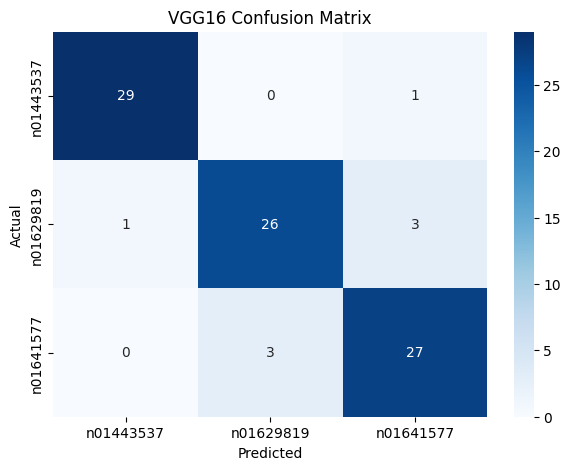

**VGG16:** 82 of 90 test images were classified correctly.

- Accuracy: 91.11%
- Precision: 0.9114
- Recall: 0.9111
- F1 Score: 0.9111
- n01443537: 29 of 30 correct (96.67%)
- n01629819: 26 of 30 correct (86.67%)
- n01641577: 27 of 30 correct (90.00%)
- Most common error: n01629819 predicted as n01641577 (3 images)

In [24]:
evaluate_model("VGG16", vgg_model, X_test_vgg, y_test)

### MobileNetV2

In [25]:
X_train_mobilenet = prepare_images(X_train, mobilenet_preprocess)
X_val_mobilenet = prepare_images(X_val, mobilenet_preprocess)
X_test_mobilenet = prepare_images(X_test, mobilenet_preprocess)

In [26]:
base_mobilenet = MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

base_mobilenet.trainable = False

x = base_mobilenet.output
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.3)(x)
output = Dense(3, activation='softmax')(x)

mobilenet_model = Model(
    inputs=base_mobilenet.input,
    outputs=output
)

mobilenet_model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

mobilenet_model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer_2[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,422,339 (9.24 MB)

 Trainable params: 164,355 (642.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [27]:
history_mobilenet = mobilenet_model.fit(
    X_train_mobilenet,
    y_train,
    validation_data=(X_val_mobilenet, y_val),
    epochs=EPOCHS,
    batch_size=32,
    callbacks=[make_early_stop()],
    verbose=1
)

Epoch 1/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 24s 1s/step - accuracy: 0.7238 - loss: 0.7359 - val_accuracy: 0.9444 - val_loss: 0.1777
Epoch 2/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 51ms/step - accuracy: 0.9286 - loss: 0.1924 - val_accuracy: 0.9667 - val_loss: 0.1019
Epoch 3/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - accuracy: 0.9452 - loss: 0.1239 - val_accuracy: 0.9444 - val_loss: 0.1328
Epoch 4/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - accuracy: 0.9643 - loss: 0.0955 - val_accuracy: 0.9667 - val_loss: 0.0761
Epoch 5/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step - accuracy: 0.9857 - loss: 0.0560 - val_accuracy: 0.9778 - val_loss: 0.0607
Epoch 6/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step - accuracy: 0.9857 - loss: 0.0410 - val_accuracy: 0.9778 - val_loss: 0.0571
Epoch 7/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - accuracy: 0.9929 - loss: 0.0316 - val_accuracy: 0.9667 - val_loss: 0.0780
Epoch 8/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - accuracy: 0.9976 - loss: 0.0280 - val_accuracy: 0.9778 - va

              precision    recall  f1-score   support

   n01443537     1.0000    1.0000    1.0000        30
   n01629819     0.9286    0.8667    0.8966        30
   n01641577     0.8750    0.9333    0.9032        30

    accuracy                         0.9333        90
   macro avg     0.9345    0.9333    0.9333        90
weighted avg     0.9345    0.9333    0.9333        90



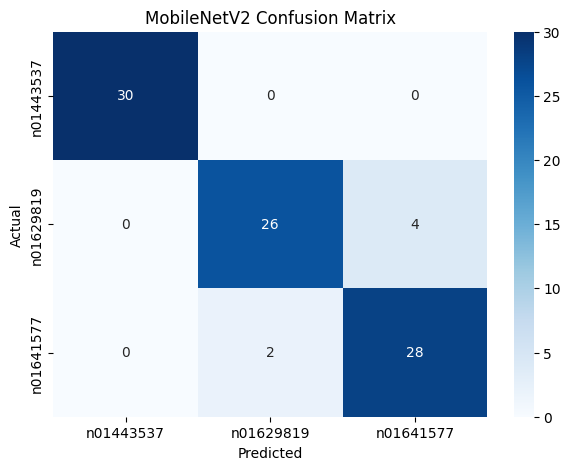

**MobileNetV2:** 84 of 90 test images were classified correctly.

- Accuracy: 93.33%
- Precision: 0.9345
- Recall: 0.9333
- F1 Score: 0.9333
- n01443537: 30 of 30 correct (100.00%)
- n01629819: 26 of 30 correct (86.67%)
- n01641577: 28 of 30 correct (93.33%)
- Most common error: n01629819 predicted as n01641577 (4 images)

In [28]:
evaluate_model("MobileNetV2", mobilenet_model, X_test_mobilenet, y_test)

### ResNet50

In [29]:
X_train_resnet = prepare_images(X_train, resnet_preprocess)
X_val_resnet = prepare_images(X_val, resnet_preprocess)
X_test_resnet = prepare_images(X_test, resnet_preprocess)

In [30]:
resnet_base = ResNet50(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

resnet_base.trainable = False

x = resnet_base.output
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.3)(x)
output = Dense(3, activation='softmax')(x)

resnet_model = Model(inputs=resnet_base.input, outputs=output)

resnet_model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

resnet_model.summary()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 230, 230,  │          0 │ input_layer_3[0]… │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 56, 56,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 56, 56,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 56, 56,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 56, 56,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 56, 56,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_3_c

 Total params: 23,850,371 (90.98 MB)

 Trainable params: 262,659 (1.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [31]:
history_resnet = resnet_model.fit(
    X_train_resnet,
    y_train,
    validation_data=(X_val_resnet, y_val),
    epochs=EPOCHS,
    batch_size=32,
    callbacks=[make_early_stop()],
    verbose=1
)

Epoch 1/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 27s 1s/step - accuracy: 0.7548 - loss: 0.6690 - val_accuracy: 0.9111 - val_loss: 0.1955
Epoch 2/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 155ms/step - accuracy: 0.9405 - loss: 0.1222 - val_accuracy: 0.9556 - val_loss: 0.1609
Epoch 3/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 122ms/step - accuracy: 0.9714 - loss: 0.0763 - val_accuracy: 0.9556 - val_loss: 0.1845
Epoch 4/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 116ms/step - accuracy: 0.9786 - loss: 0.0608 - val_accuracy: 0.9111 - val_loss: 0.1927
Epoch 5/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 127ms/step - accuracy: 0.9905 - loss: 0.0251 - val_accuracy: 0.9444 - val_loss: 0.1584
Epoch 6/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 116ms/step - accuracy: 0.9976 - loss: 0.0107 - val_accuracy: 0.9556 - val_loss: 0.1710
Epoch 7/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 117ms/step - accuracy: 1.0000 - loss: 0.0093 - val_accuracy: 0.9444 - val_loss: 0.1723
Epoch 8/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 117ms/step - accuracy: 0.9976 - loss: 0.0109 - val_accuracy: 0.94

              precision    recall  f1-score   support

   n01443537     1.0000    0.9667    0.9831        30
   n01629819     0.8750    0.9333    0.9032        30
   n01641577     0.8966    0.8667    0.8814        30

    accuracy                         0.9222        90
   macro avg     0.9239    0.9222    0.9225        90
weighted avg     0.9239    0.9222    0.9225        90



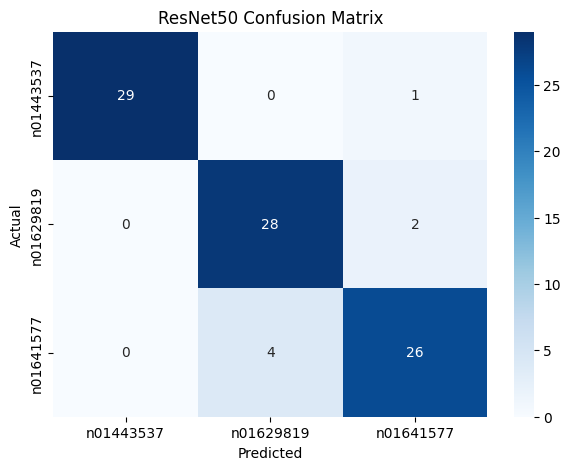

**ResNet50:** 83 of 90 test images were classified correctly.

- Accuracy: 92.22%
- Precision: 0.9239
- Recall: 0.9222
- F1 Score: 0.9225
- n01443537: 29 of 30 correct (96.67%)
- n01629819: 28 of 30 correct (93.33%)
- n01641577: 26 of 30 correct (86.67%)
- Most common error: n01641577 predicted as n01629819 (4 images)

In [32]:
evaluate_model("ResNet50", resnet_model, X_test_resnet, y_test)

## Final Comparison of All Models

In [33]:
table = [
    "| Model | Test Accuracy | Precision | Recall | F1 Score |",
    "|---|---:|---:|---:|---:|"
]

for name, scores in results.items():
    table.append(
        f"| {name} | {scores['Accuracy']:.2%} | {scores['Precision']:.4f} "
        f"| {scores['Recall']:.4f} | {scores['F1 Score']:.4f} |"
    )

display(Markdown("\n".join(table)))

| Model | Test Accuracy | Precision | Recall | F1 Score |
|---|---:|---:|---:|---:|
| Custom CNN | 81.11% | 0.8132 | 0.8111 | 0.8117 |
| VGG16 | 91.11% | 0.9114 | 0.9111 | 0.9111 |
| MobileNetV2 | 93.33% | 0.9345 | 0.9333 | 0.9333 |
| ResNet50 | 92.22% | 0.9239 | 0.9222 | 0.9225 |

In [34]:
test_total = len(y_test)
image_value = 100 / test_total

def correct_images(name):
    return round(results[name]['Accuracy'] * test_total)

best_correct = max(correct_images(name) for name in results)
worst_correct = min(correct_images(name) for name in results)

best_models = [name for name in results if correct_images(name) == best_correct]
worst_models = [name for name in results if correct_images(name) == worst_correct]

comparisons = []

for name in ["VGG16", "MobileNetV2", "ResNet50"]:
    difference = correct_images(name) - correct_images("Custom CNN")

    if difference > 0:
        comparisons.append(f"- {name} correctly classified {difference} more test image(s) than the custom CNN.")
    elif difference < 0:
        comparisons.append(f"- {name} correctly classified {-difference} fewer test image(s) than the custom CNN.")
    else:
        comparisons.append(f"- {name} correctly classified the same number of test images as the custom CNN.")

comparison_text = "\n".join(comparisons)

display(Markdown(f"""
### Overall Conclusion

- **Highest test accuracy:** {' and '.join(best_models)} with {best_correct} of {test_total} images correct ({best_correct / test_total:.2%}).
- **Lowest test accuracy:** {' and '.join(worst_models)} with {worst_correct} of {test_total} images correct ({worst_correct / test_total:.2%}).

{comparison_text}

The pretrained models start with features learned from ImageNet, while the custom CNN learns only from the 420 training images. All four models were tested on the same {test_total} images. Each image is worth about {image_value:.2f} percentage points, so a difference of one or two images should not be treated as meaningful.
"""))


### Overall Conclusion

- **Highest test accuracy:** MobileNetV2 with 84 of 90 images correct (93.33%).
- **Lowest test accuracy:** Custom CNN with 73 of 90 images correct (81.11%).

- VGG16 correctly classified 9 more test image(s) than the custom CNN.
- MobileNetV2 correctly classified 11 more test image(s) than the custom CNN.
- ResNet50 correctly classified 10 more test image(s) than the custom CNN.

The pretrained models start with features learned from ImageNet, while the custom CNN learns only from the 420 training images. All four models were tested on the same 90 images. Each image is worth about 1.11 percentage points, so a difference of one or two images should not be treated as meaningful.
